# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import HLSBurnScarsDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 540


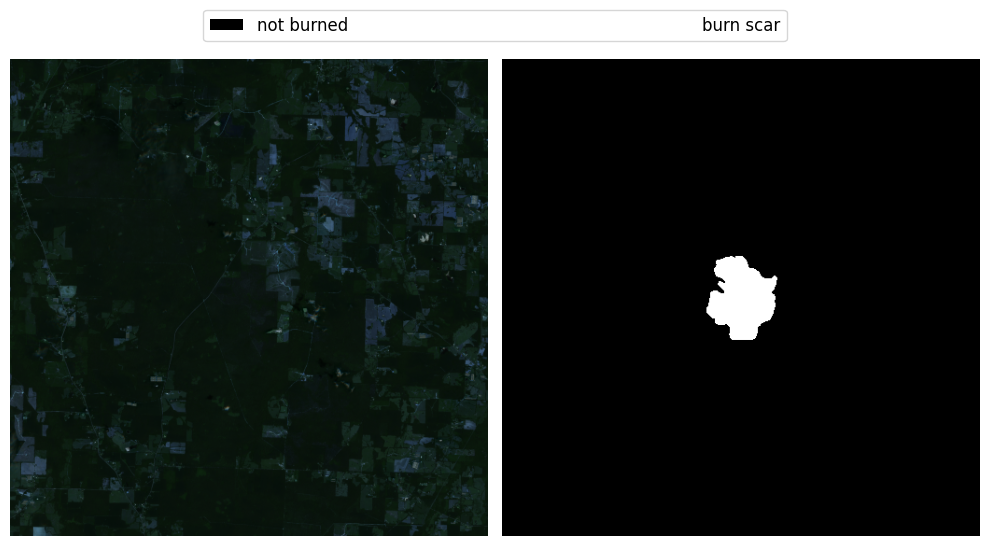

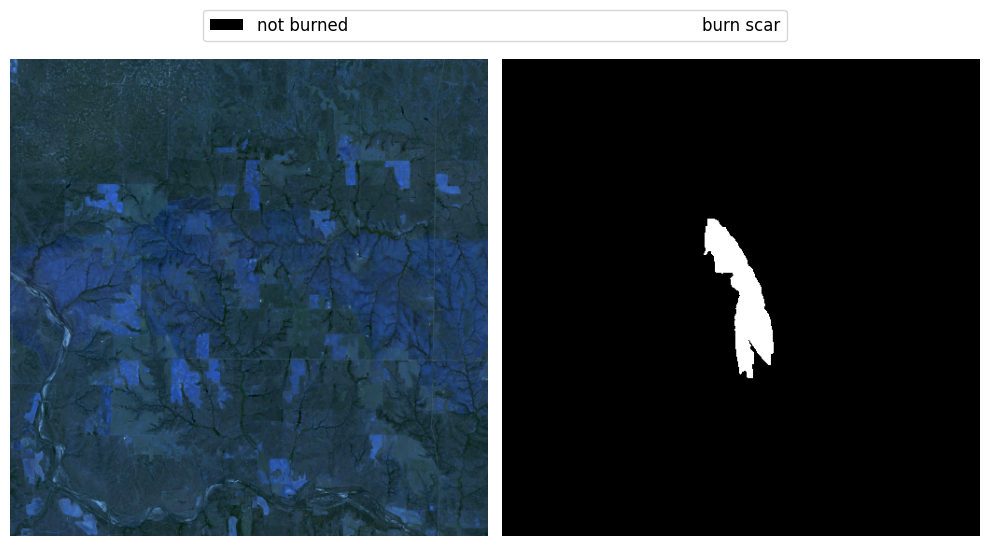

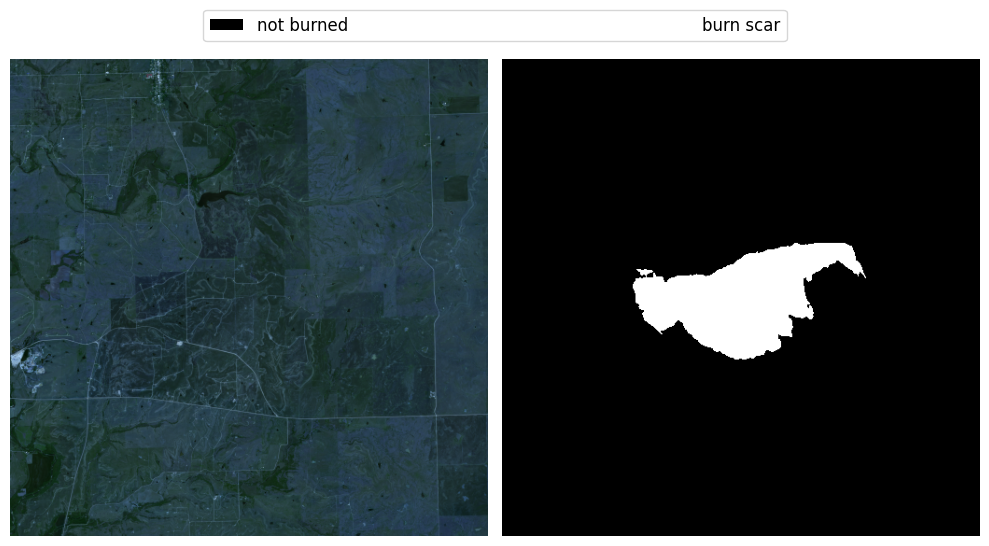

In [ ]:
dataset_config = {
    "data_dir": "./data/hlsburnscars/training",
    "selection": "rgb"
}
dataset = HLSBurnScarsDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(2);
dataset.show_image(250);
dataset.show_image(400);

In [11]:
dataset.data_distribution_table()

,Number of pixels
not burned,123949681.0
burn scar,16851231.0


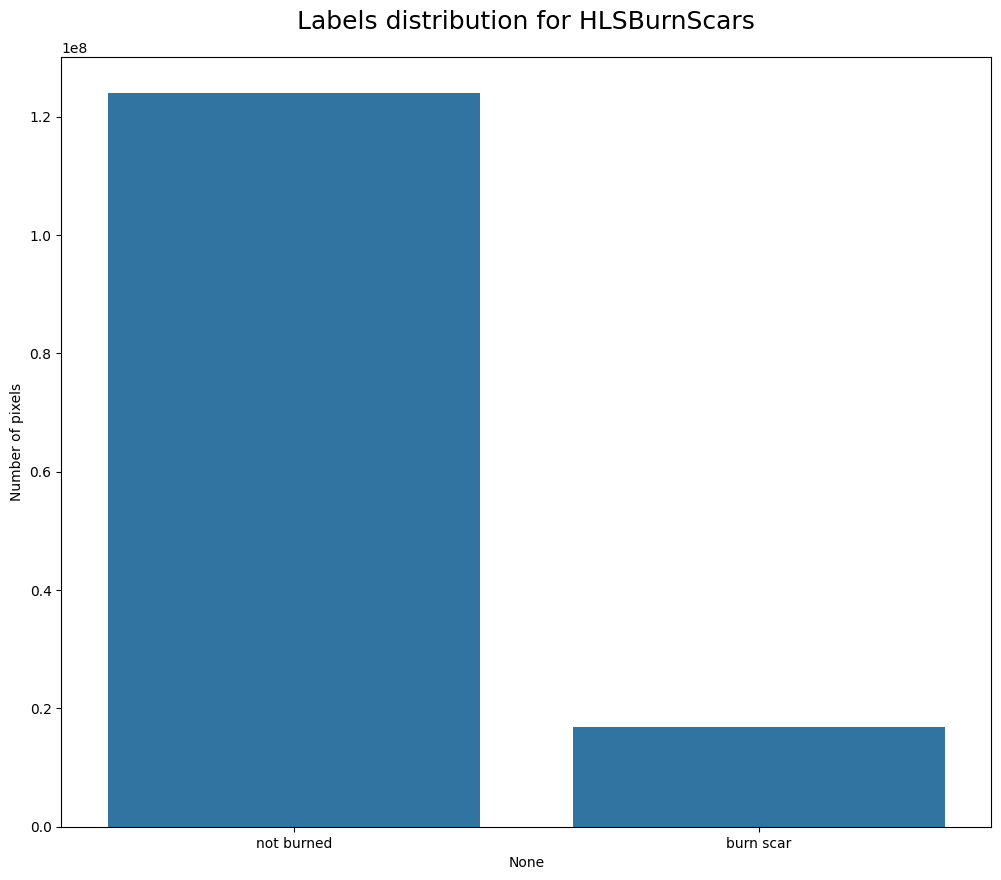

In [12]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/hlsburnscars/training",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = HLSBurnScarsDataset(train_dataset_config)
len(train_dataset)

540

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/hlsburnscars"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [37]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-04-20 07:37:07,200 INFO Starting training.
training: 100%|██████████| 34/34 [00:12<00:00,  2.82it/s]
2026-04-20 07:37:19,772 INFO epoch: 1, time: 12, loss:  0.37928
testing on train set: 100%|██████████| 34/34 [00:04<00:00,  7.78it/s]
2026-04-20 07:37:26,308 INFO IOU:0.4134016042739877, IOU mean:0.4226299135951544, IOU per Class:[0.73202362 0.11323621]
training: 100%|██████████| 34/34 [00:12<00:00,  2.82it/s]
2026-04-20 07:37:38,362 INFO epoch: 2, time: 12, loss:  0.31073
testing on train set: 100%|██████████| 34/34 [00:04<00:00,  7.96it/s]
2026-04-20 07:37:42,650 INFO IOU:0.4898246341281467, IOU mean:0.4898246341281467, IOU per Class:[0.86791074 0.11173853]
training: 100%|██████████| 34/34 [00:11<00:00,  2.86it/s]
2026-04-20 07:37:54,535 INFO epoch: 3, time: 12, loss:  0.28593
testing on train set: 100%|██████████| 34/34 [00:04<00:00,  7.70it/s]
2026-04-20 07:37:58,965 INFO IOU:0.4898246341281467, IOU mean:0.4898246341281467, IOU per Class:[0.86791074 0.11173853]
training: 100%|█

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/hlsburnscars/validation",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = HLSBurnScarsDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/hlsburnscars/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

264


2026-04-20 07:58:49,621 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hlsburnscars/checkpoint.pth.tar
2026-04-20 07:58:54,397 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hlsburnscars/checkpoint.pth.tar at epoch 51
testing on test set: 100%|██████████| 66/66 [00:02<00:00, 23.66it/s]


[{'IOU': 0.8354694953123892,
  'IOU mean': 0.5606019003362531,
  'IOU per Class': array([0.9015663, 0.2196375])}]

## Predictions

2026-04-20 07:59:11,388 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hlsburnscars/checkpoint.pth.tar
2026-04-20 07:59:14,104 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hlsburnscars/checkpoint.pth.tar at epoch 51


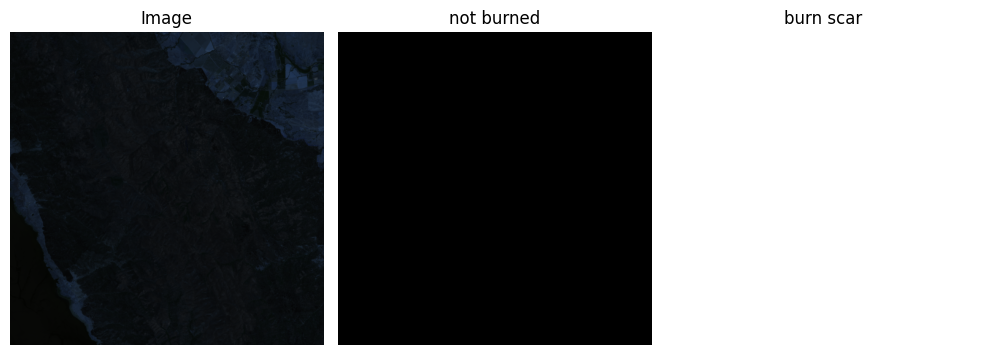

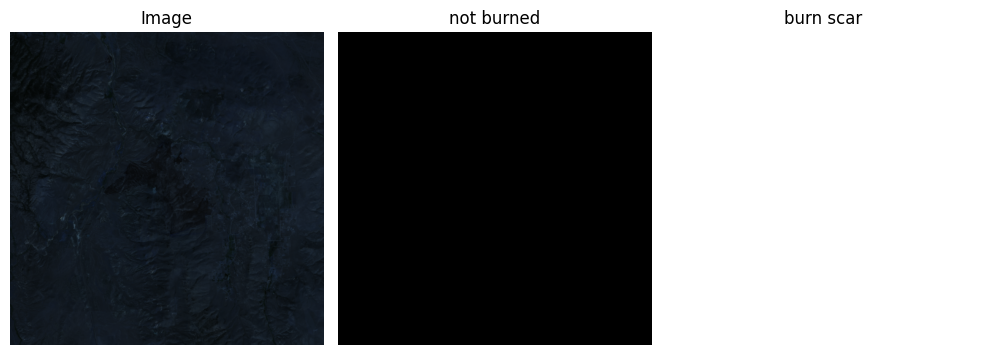

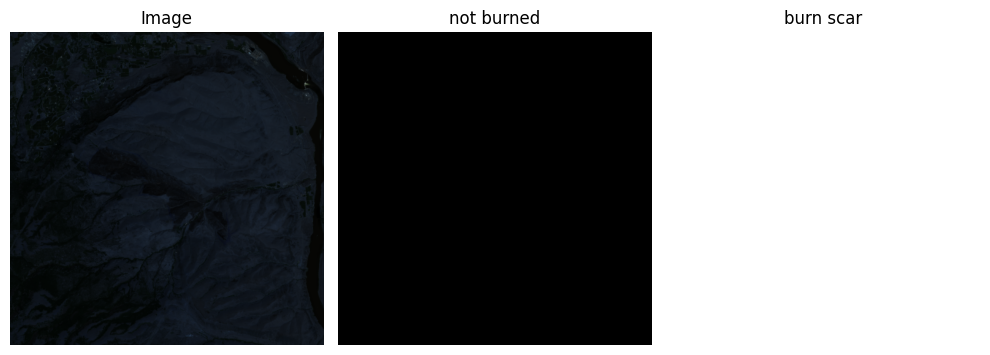

In [ ]:
model_path = "./data/experiments/hlsburnscars/checkpoint.pth.tar"
labels = ["not burned","burn scar"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('./data/hlsburnscars/validation/subsetted_512x512_HLS.S30.T10SEH.2018190.v1.4_merged.tif')[:,:,:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/hlsburnscars/validation/subsetted_512x512_HLS.S30.T10TGK.2019245.v1.4_merged.tif')[:,:,:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/hlsburnscars/validation/subsetted_512x512_HLS.S30.T10TGT.2020218.v1.4_merged.tif')[:,:,:3]
fig = model.predict_masks(image, labels, transform)